In [19]:
from langgraph.graph import StateGraph, START, END
from langchain_huggingface import HuggingFacePipeline
from typing import TypedDict
from dotenv import load_dotenv
import os

In [20]:
load_dotenv()
hf_token = os.getenv("HUGGINGFACE_API_KEY")

In [21]:
model = HuggingFacePipeline.from_model_id(
    model_id="Qwen/Qwen2.5-0.5B-Instruct",
    task="text-generation",
    pipeline_kwargs={
        "max_new_tokens": 150,
        "temperature": 0.7,
        "do_sample": True
    }
)

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 441.06it/s]


In [22]:
# state
class BatsmanState(TypedDict):

    runs: int
    balls: int
    fours: int
    sixes: int

    strick_rate: float
    balls_per_boundry: float
    boundry_percent: float

    summary: str

In [ ]:
def calculate_strick_rate(state: BatsmanState):

    sr = (state['runs']/state['balls'])*100

    return {'strick_rate':sr}

In [24]:
def calculate_balls_per_boundry(state: BatsmanState):

    bpb = state['balls']/(state['fours']+state['sixes'])

    return {'balls_per_boundry':bpb}

In [25]:
def calculate_boundry_percent(state: BatsmanState):

    boundry_percent = (((state['fours'] * 4) + (state['sixes'] * 6))/state['runs'])*100

    return {'boundry_percent':boundry_percent}

In [28]:
def summary(state: BatsmanState):

    summary = f"""
    Strike Rate - {state['strick_rate']}
    Balls Per Boundary - {state['balls_per_boundry']}
    Boundary Percent - {state['boundry_percent']}
    """

    return {'summary': summary}


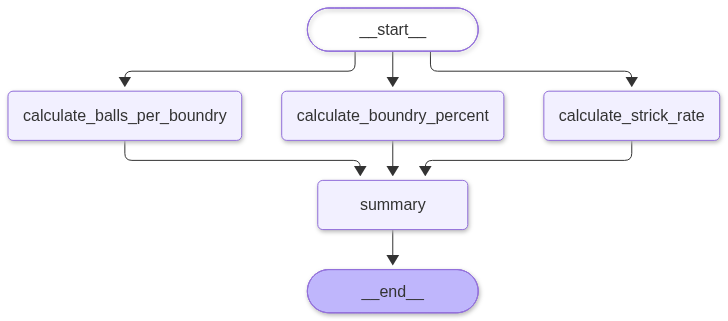

In [ ]:
# create Graph
graph = StateGraph(BatsmanState)

# add nodes
graph.add_node('calculate_strick_rate',calculate_strick_rate)
graph.add_node('calculate_balls_per_boundry',calculate_balls_per_boundry)
graph.add_node('calculate_boundry_percent',calculate_boundry_percent)
graph.add_node('summary',summary)


# add edges
graph.add_edge(START,'calculate_strick_rate')
graph.add_edge(START,'calculate_balls_per_boundry')
graph.add_edge(START,'calculate_boundry_percent')
graph.add_edge('calculate_strick_rate','summary')
graph.add_edge('calculate_balls_per_boundry','summary')
graph.add_edge('calculate_boundry_percent','summary')
graph.add_edge('summary',END)

# compile
workflow = graph.compile()


In [33]:
initial_state = {
    'runs': 100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}

workflow.invoke(initial_state)



{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'strick_rate': 0.02,
 'balls_per_boundry': 5.0,
 'boundry_percent': 48.0,
 'summary': '\n    Strike Rate - 0.02\n    Balls Per Boundary - 5.0\n    Boundary Percent - 48.0\n    '}